## OpenAI API_KET 세팅

In [1]:
# imports

import os
from dotenv import load_dotenv

In [2]:
# Initialization

load_dotenv(override=True)

openai_api_key = os.getenv('OPENAI_API_KEY')
if openai_api_key:
    print(f"OpenAI API Key exists and begins {openai_api_key[:8]}")
else:
    print("OpenAI API Key not set")

OpenAI API Key exists and begins sk-proj-


# Generate  images

## Images API

https://developers.openai.com/api/reference/resources/images


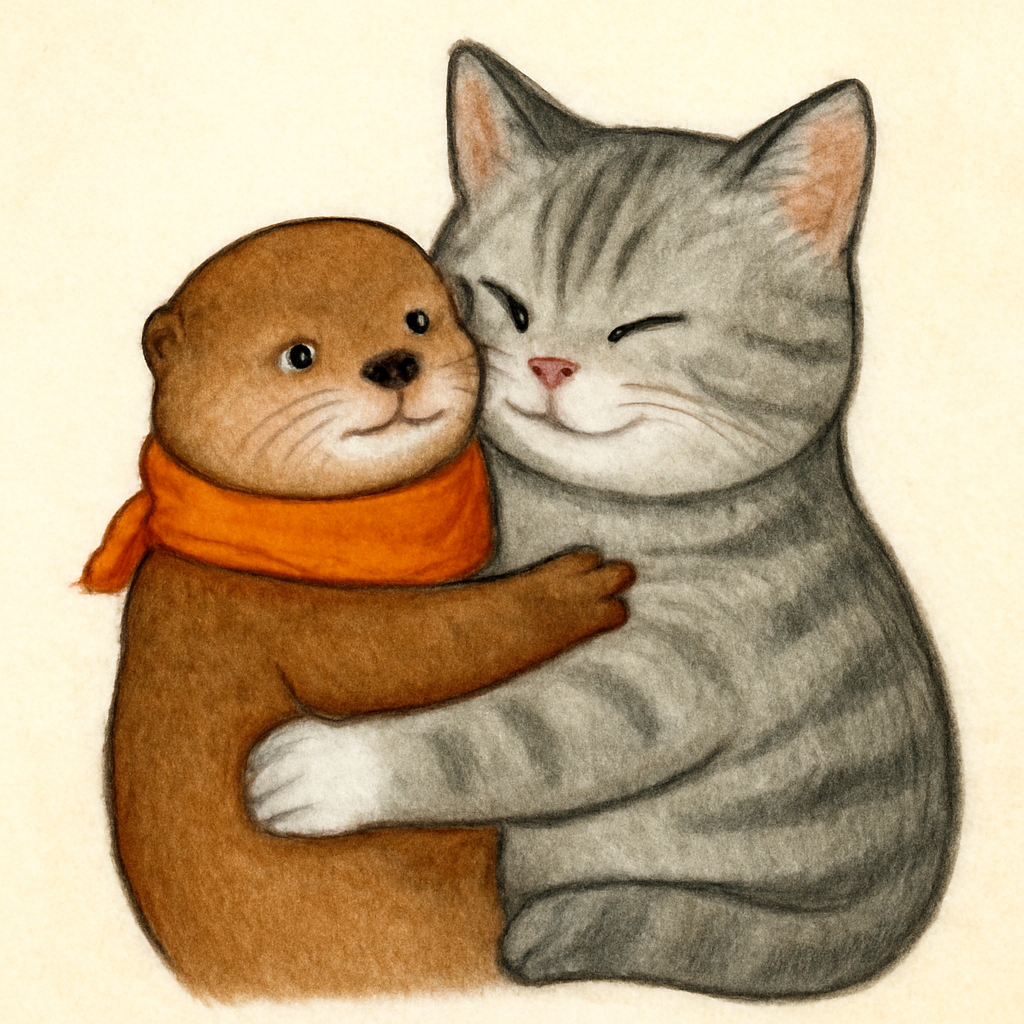

이미지 저장 완료!


In [9]:
from openai import OpenAI
from IPython.display import display, Image as IPImage
import base64

# OpenAI 클라이언트 초기화 (환경변수 OPENAI_API_KEY 자동 참조)
client = OpenAI()

# 이미지 생성 요청
response = client.images.generate(
    model="gpt-image-1-mini",       # 사용할 이미지 생성 모델
    prompt="주황색 스카프를 두른 수달을 안고 있는 회색 줄무늬 고양이",  # 이미지 설명 텍스트
    size="1024x1024",               # 이미지 크기 (가로x세로 픽셀)
    quality="low"                   # 품질 설정: low(낮음) / medium(중간) / high(높음)
                                    # low일수록 생성 속도 빠르고 비용 저렴
)

# 응답에서 base64 인코딩된 이미지 데이터 추출
# response.data는 생성된 이미지 목록 (기본 n=1이므로 [0]으로 첫 번째 이미지 접근)
image_base64 = response.data[0].b64_json

# base64 문자열 → 실제 이미지 바이트로 디코딩
# base64: 바이너리 데이터를 텍스트로 인코딩하는 방식
image_bytes = base64.b64decode(image_base64)

# 디코딩된 바이트를 PNG 파일로 저장
# "wb" 모드: 바이너리 쓰기 (w=write, b=binary)
with open("고양이와_수달.png", "wb") as f:
    f.write(image_bytes)

# 주피터 노트북 셀 안에 이미지 바로 출력
# IPImage: 바이트 데이터를 노트북이 렌더링할 수 있는 이미지 객체로 변환
# display(): 노트북 출력 영역에 해당 객체를 렌더링
display(IPImage(data=image_bytes))

print("이미지 저장 완료!")

## Infographics

https://github.com/openai/openai-cookbook/blob/main/examples/multimodal/image-gen-1.5-prompting_guide.ipynb


In [26]:
import os
import base64
from openai import OpenAI

client = OpenAI()

os.makedirs("./images/input_images", exist_ok=True)
os.makedirs("./images/output_images", exist_ok=True)

def save_image(result, filename: str) -> None:
    """
    Saves the first returned image to the given filename inside the output_images folder.
    """
    image_base64 = result.data[0].b64_json
    out_path = os.path.join("./images/output_images", filename)
    with open(out_path, "wb") as f:
        f.write(base64.b64decode(image_base64))

In [28]:
# 자동 커피 머신(예: Jura)의 작동 원리와 흐름을 설명하는 인포그래픽 생성
# 원두 바스켓 → 분쇄 → 저울 → 물탱크 → 보일러 등 전체 과정을 기술적·시각적으로 표현
prompt = """
자동 커피 머신(Jura 등)의 작동 원리와 흐름을 상세한 인포그래픽으로 그려주세요.
원두 바스켓, 분쇄 과정, 저울, 물탱크, 보일러 등 각 구성 요소를 포함하고,
전체 흐름을 기술적이고 시각적으로 이해할 수 있도록 표현해주세요.
"""

# 이미지 생성 요청
# - gpt-image-1.5: 고품질 이미지 생성 모델
# - 응답은 항상 base64 형식으로 반환됨
result = client.images.generate(
    model="gpt-image-1-mini",                  # 이미지 생성 모델
    prompt=prompt,                          # 생성할 이미지 설명
    size="1024x1024",               # 이미지 크기 (가로x세로 픽셀)
    quality="medium",                         # 품질: low / medium / high
    n=1                                     # 생성할 이미지 수
)

# 생성된 이미지를 파일로 저장
# save_image(): base64 디코딩 후 PNG 파일로 저장하는 함수
save_image(result, "infographic_coffee_machine.png")

## Logo Generation

https://github.com/openai/openai-cookbook/blob/main/examples/multimodal/image-gen-1.5-prompting_guide.ipynb


In [ ]:
import os
import base64
from openai import OpenAI

client = OpenAI()

In [29]:
prompt = """
"Field & Flour"라는 이름의 동네 베이커리를 위한 오리지널 로고를 만들어주세요.
따뜻하고, 단순하며, 시대를 초월한 느낌이어야 합니다.
깔끔한 벡터 형태, 강한 실루엣, 균형 잡힌 여백을 사용하세요.
작은 크기와 큰 크기 모두에서 명확하게 보이도록 세부 묘사보다 단순함을 추구하세요.
플랫 디자인, 최소한의 선, 꼭 필요한 경우가 아니면 그라데이션 없이.
단색 배경. 여유 있는 여백을 두고 중앙에 로고 하나만 배치. 워터마크 없음.
"""

# 이미지 생성 요청
# - n=4: 로고 4가지 버전 동시 생성
# - gpt-image-1.5는 n > 1 지원 (gpt-image-2는 n=1만 지원)
result = client.images.generate(
    model="gpt-image-1-mini",      # 이미지 생성 모델
    prompt=prompt,              # 로고 설명 프롬프트
    n=4                         # 생성할 이미지 수 (4가지 버전)
)

# 생성된 4개의 이미지를 각각 별도 파일로 저장
# enumerate(start=1): 인덱스를 1부터 시작 (logo_1.png ~ logo_4.png)
for i, item in enumerate(result.data, start=1):

    # 각 이미지의 base64 데이터 추출
    image_base64 = item.b64_json

    # base64 문자열 → 바이너리 바이트로 디코딩
    image_bytes = base64.b64decode(image_base64)

    # 파일명에 번호를 붙여 순서대로 저장
    # 예: logo_generation_1.png ~ logo_generation_4.png
    with open(f"./images/output_images/logo_generation_{i}.png", "wb") as f:
        f.write(image_bytes)

    print(f"로고 {i}번 저장 완료: logo_generation_{i}.png")

print("전체 로고 생성 및 저장 완료!")

로고 1번 저장 완료: logo_generation_1.png
로고 2번 저장 완료: logo_generation_2.png
로고 3번 저장 완료: logo_generation_3.png
로고 4번 저장 완료: logo_generation_4.png
전체 로고 생성 및 저장 완료!


## 함수 형태로 프롬프트 재사용

In [10]:
# Some imports for handling images

import base64
from io import BytesIO
from PIL import Image

In [12]:
# OpenAI 클라이언트 초기화 (환경변수 OPENAI_API_KEY 자동 참조)
openai = OpenAI()

In [17]:
def artist(city):
    # 이미지 생성 요청
    # - 해당 도시의 관광지와 특색을 팝아트 스타일로 표현
    image_response = openai.images.generate(
        model="gpt-image-1-mini",           # dall-e-3 → gpt-image-1-mini (dall-e-3 서비스 종료)
        prompt=f"{city} 여행을 표현한 이미지. {city}의 유명 관광지와 고유한 특색을 생동감 넘치는 팝아트 스타일로 그려주세요",
        size="1024x1024",                   # 이미지 크기 (가로x세로 픽셀)
        n=1,                                # 생성할 이미지 수 (1장)
        # response_format="b64_json"        # gpt-image-1 계열은 항상 b64_json으로 반환되므로 불필요
    )

    # 응답에서 base64 인코딩된 이미지 데이터 추출
    # data[0]: 첫 번째(유일한) 이미지 선택
    image_base64 = image_response.data[0].b64_json

    # base64 문자열 → 바이너리 바이트로 디코딩
    image_data = base64.b64decode(image_base64)

    # 바이트 데이터를 메모리 내 파일처럼 다루기 위해 BytesIO로 감싼 후
    # PIL Image 객체로 변환하여 반환
    return Image.open(BytesIO(image_data))

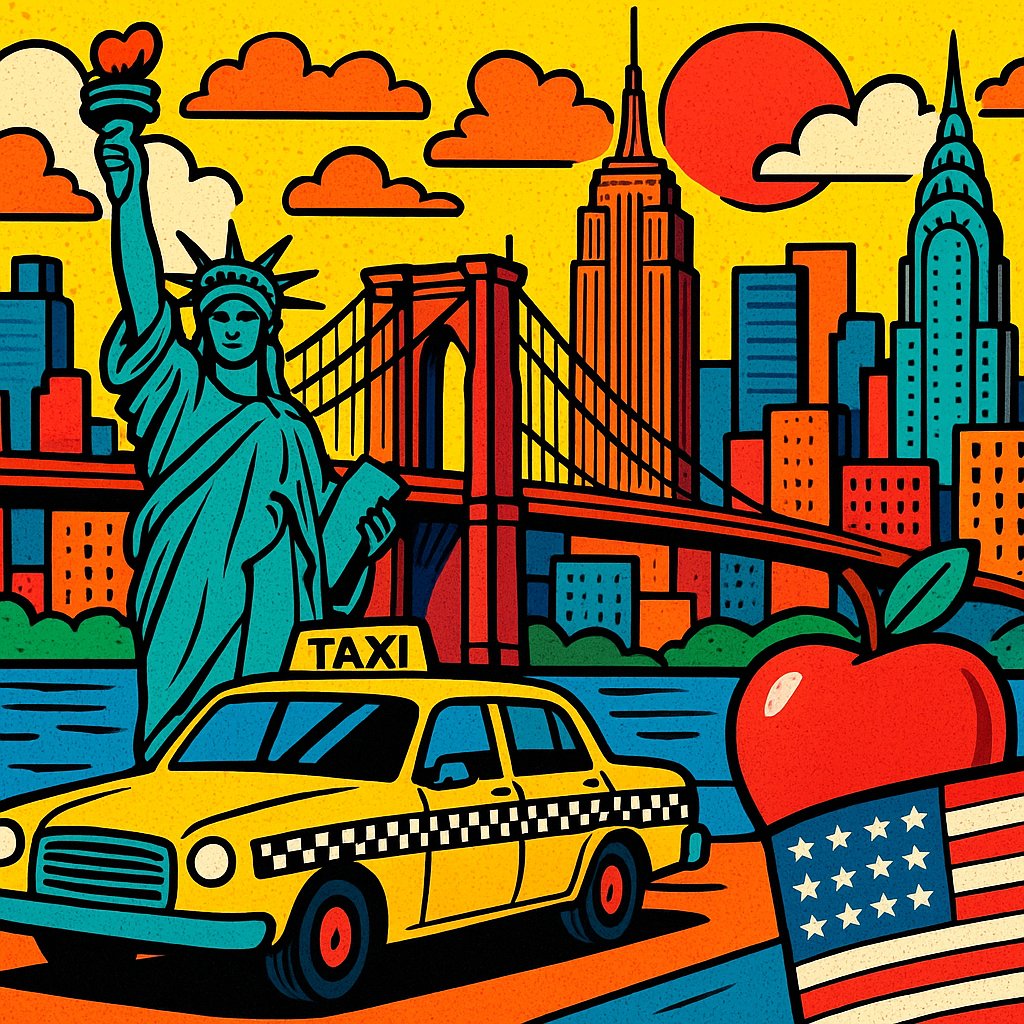

In [18]:
image = artist("뉴욕")
display(image)

# Analyze images



https://developers.openai.com/api/docs/guides/images-vision?format=url&lang=python#analyze-images


https://api.nga.gov/iiif/a2e6da57-3cd1-4235-b20e-95dcaefed6c8/full/!800,800/0/default.jpg


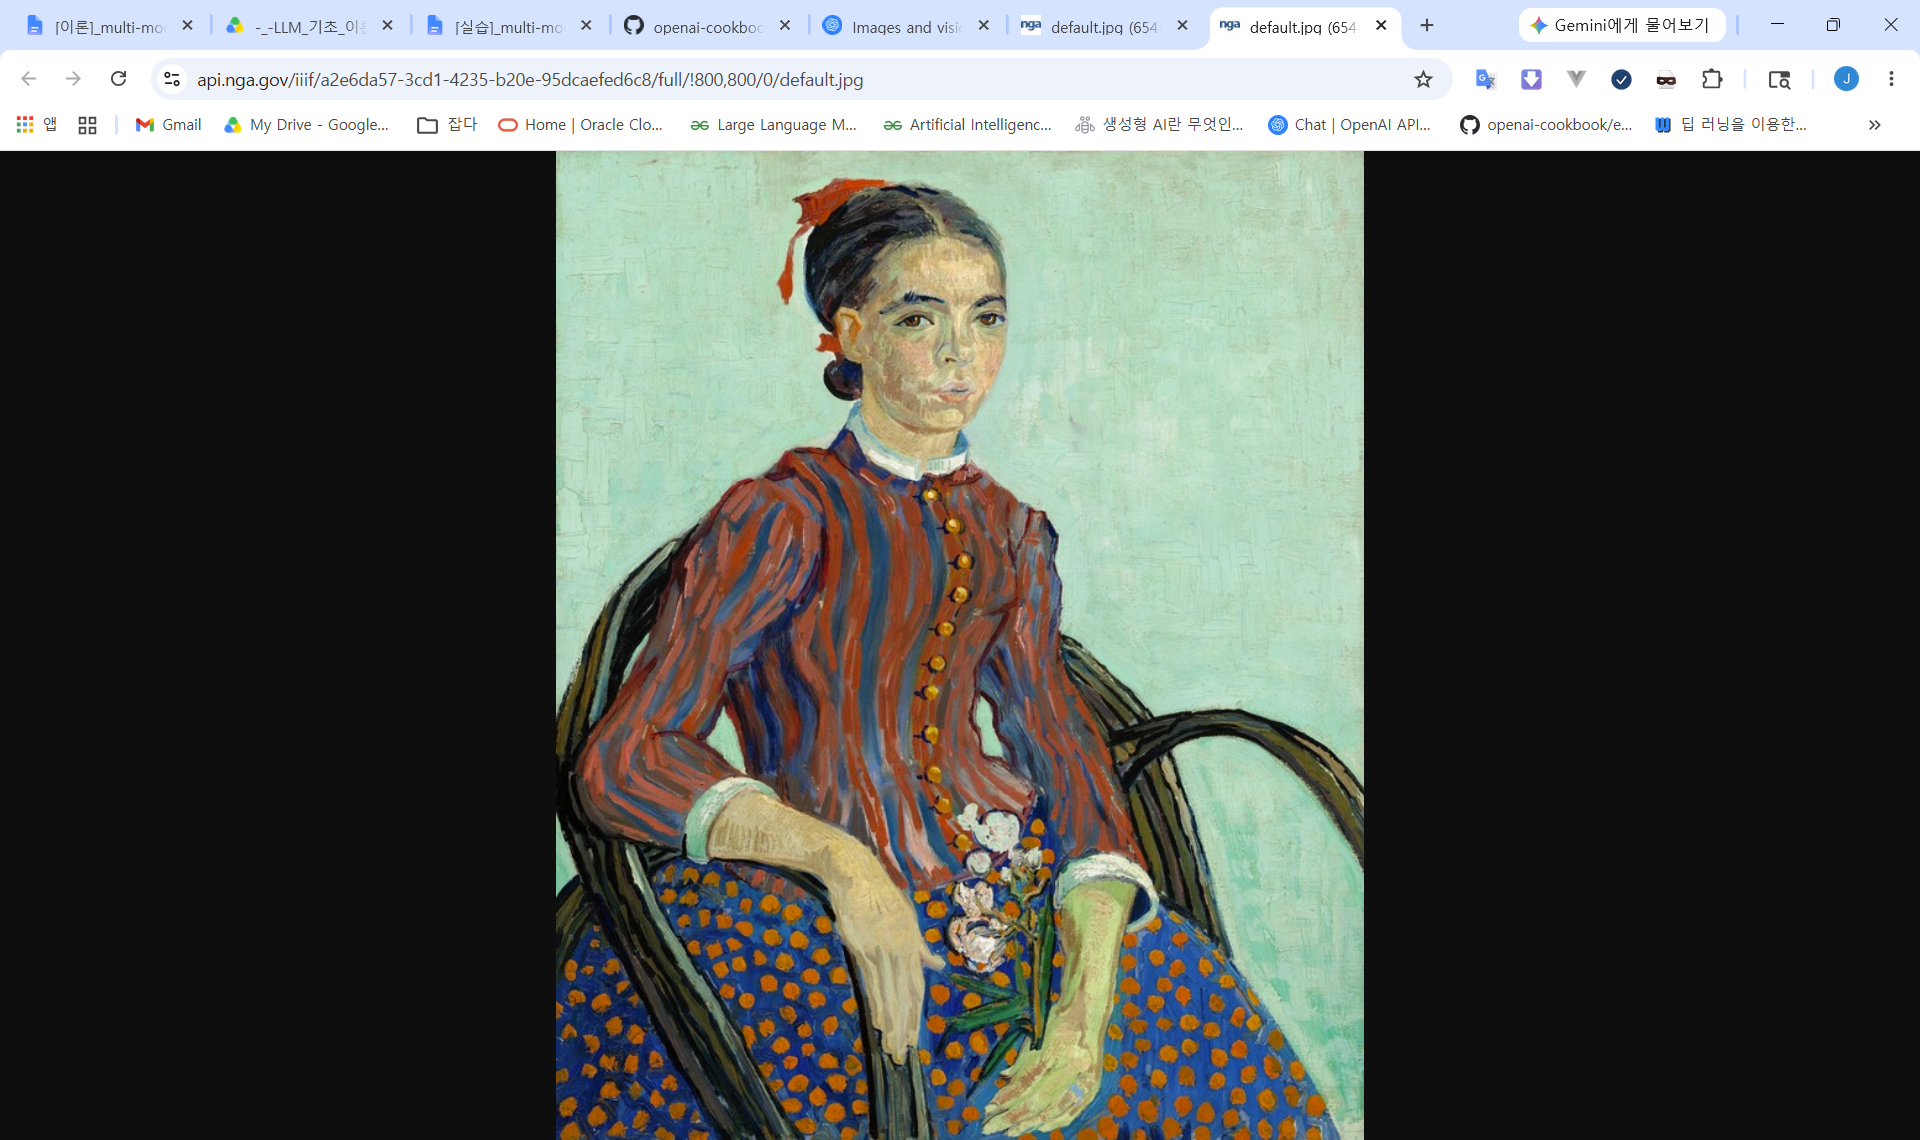

Responses API

In [31]:
from openai import OpenAI

client = OpenAI()

response = client.responses.create(
    model="gpt-4.1-mini",
    input=[{
        "role": "user",
        "content": [
            {"type": "input_text", "text": "이 이미지 머야?"},
            {
                "type": "input_image",
                "image_url": "https://api.nga.gov/iiif/a2e6da57-3cd1-4235-b20e-95dcaefed6c8/full/!800,800/0/default.jpg",
            },
        ],
    }],
)

print(response.output_text)

이 이미지는 빈센트 반 고흐의 초상화 스타일을 연상시키는 그림입니다. 붓 터치가 강하고 생동감이 느껴지는 색채의 표현이 특징적이며, 옷이나 배경에서도 고흐 특유의 화풍이 나타납니다. 여성 인물이 의자에 앉아 있는 모습이며, 전통 복장을 입고 손에 꽃을 들고 있는 장면을 담고 있습니다. 

혹시 더 구체적인 정보나 그림의 출처가 궁금하면 알려주세요!


Chat Completions API

In [32]:
from openai import OpenAI

client = OpenAI()

# Chat Completions API로 이미지 분석 요청
# - Responses API의 input_text → content 내 text 타입으로 변경
# - Responses API의 input_image → content 내 image_url 타입으로 변경
response = client.chat.completions.create(
    model="gpt-4.1-mini",           # 사용할 모델 (비전 기능 지원)
    messages=[{
        "role": "user",
        "content": [
            {
                "type": "text",     # 텍스트 메시지
                "text": "이 이미지 머야?"
            },
            {
                "type": "image_url",    # 이미지 URL 입력
                "image_url": {
                    "url": "https://api.nga.gov/iiif/a2e6da57-3cd1-4235-b20e-95dcaefed6c8/full/!800,800/0/default.jpg"
                }
            },
        ],
    }],
)

# 응답 텍스트 추출
# - Responses API: response.output_text
# - Chat Completions API: response.choices[0].message.content
print(response.choices[0].message.content)

이 이미지는 빈센트 반 고흐(Vincent van Gogh)의 유명한 작품 중 하나인 "씨없는 자두" 또는 "Portrait of Augustine Roulin"와 비슷한 스타일의 그림처럼 보입니다. 하지만 정확히 같은 작품은 아니며, 고흐의 두꺼운 붓 터치와 강렬한 색상 표현이 느껴지는 인물 초상화입니다.

그림 속 인물은 의자에 앉아 있고, 줄무늬가 있는 빨간색 상의와 파란색 바지 또는 치마를 입고 있습니다. 머리에는 붉은색 리본이 있고, 손에 작은 꽃다발을 들고 있습니다. 배경은 단색으로 단순하게 처리돼 있어 인물에 집중할 수 있게 했습니다.

이 작품은 고흐 특유의 인상주의와 표현주의가 결합된 스타일을 보여주며, 19세기 후반 프랑스 미술의 분위기를 담고 있다고 할 수 있습니다.
